# 01 EDA: freight rates
Goal: understand what drives `posted_rate` and what is broken in the data before modelling.

In [1]:
import sys; sys.path.append('..')          # so we can import src/
import pandas as pd, numpy as np, matplotlib.pyplot as plt
from src.data import load_train, load_validation
FIG = '../reports/figures/'

train = load_train()        # Jan-Oct 2025, has posted_rate
val = load_validation()     # Nov-Dec 2025, we predict this
print(train.shape, val.shape)
print(train.date.min().date(), train.date.max().date(), '|', val.date.min().date(), val.date.max().date())
train.head()

(48000, 14) (12000, 13)
2025-01-01 2025-10-31 | 2025-11-01 2025-12-31


,load_id,pickup,delivery,pickup_lat,pickup_lon,delivery_lat,delivery_lon,distance,equipment,weight,date,market_index,quote_signal,posted_rate
0,TR-000001,Richmond,Baltimore,38.09122,-76.78906,38.16908,-72.74564,274.3,Dry Van,30658.0,2025-01-01,0.95684,2.39595,645.41
1,TR-000002,Richmond,Philadelphia,38.09122,-76.78906,39.22317,-72.96710,280.5,Reefer,17555.0,2025-01-01,0.97623,2.43355,679.97
2,TR-000003,Philadelphia,Green Bay,39.22317,-72.96710,44.30296,-87.52871,967.8,Dry Van,31721.0,2025-01-01,1.00971,1.84491,1802.54
3,TR-000004,Hartford,Atlanta,39.55328,-72.18051,34.84933,-86.28940,965.4,Dry Van,32333.0,2025-01-01,0.94518,1.87712,1827.28
4,TR-000005,Dallas,Nashville,31.83025,-94.38343,35.29479,-88.08915,541.9,Reefer,35183.0,2025-01-01,0.98480,2.56300,1380.28


## Chart 1: distance drives the price
Each dot is a load. Price grows almost in a straight line with miles; the colour shows equipment.

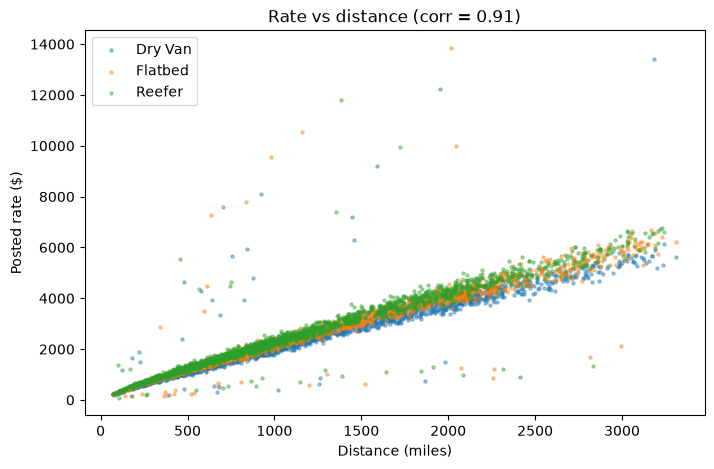

In [2]:
fig, ax = plt.subplots(figsize=(8, 5))
for eq, g in train.groupby('equipment'):
    s = g.sample(2000, random_state=0)                 # sample so the plot stays readable
    ax.scatter(s.distance, s.posted_rate, s=5, alpha=0.4, label=eq)
ax.set(xlabel='Distance (miles)', ylabel='Posted rate ($)', title='Rate vs distance (corr = %.2f)' % train.distance.corr(train.posted_rate))
ax.legend(); fig.savefig(FIG + '01_rate_vs_distance.png', dpi=130, bbox_inches='tight')

## Chart 2: rate per mile and its outliers
Dividing by distance removes the biggest effect, so we can compare short and long loads. Most loads sit near $2.15/mile. Two separate error groups stand out: ~340 loads above $4/mile (2-6x too high) and ~340 below $1.30/mile (far too cheap). That's about 1.4% of rows, likely data-entry errors.

0.001     0.44
0.010     1.67
0.500     2.15
0.990     3.18
0.999    10.07
Name: rpm, dtype: float64
equipment
Dry Van    2.05
Flatbed    2.22
Reefer     2.31
Name: rpm, dtype: float64
too high (>4/mi): 340 | too low (<1.3/mi): 337


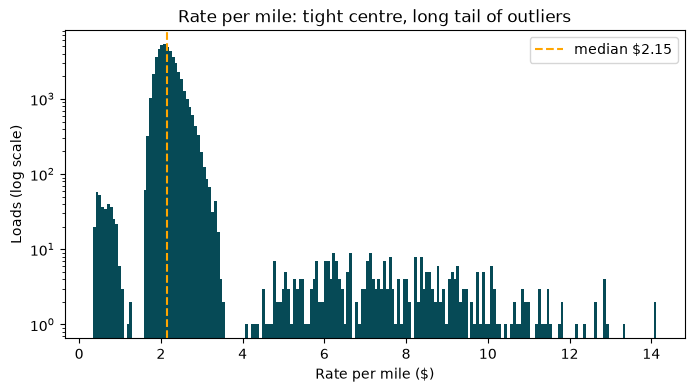

In [3]:
train['rpm'] = train.posted_rate / train.distance       # rate per mile
print(train.rpm.quantile([0.001, 0.01, 0.5, 0.99, 0.999]).round(2))
print(train.groupby('equipment').rpm.median().round(2))   # Reefer > Flatbed > Dry Van
print('too high (>4/mi):', (train.rpm > 4).sum(), '| too low (<1.3/mi):', (train.rpm < 1.3).sum())

fig, ax = plt.subplots(figsize=(8, 4))
ax.hist(train.rpm, bins=200, color='#064A56')
ax.set_yscale('log')                                       # log scale so the rare outliers are visible
ax.axvline(train.rpm.median(), color='orange', ls='--', label='median $%.2f' % train.rpm.median())
ax.set(xlabel='Rate per mile ($)', ylabel='Loads (log scale)', title='Rate per mile: tight centre, long tail of outliers')
ax.legend(); fig.savefig(FIG + '02_rate_per_mile.png', dpi=130, bbox_inches='tight')

## Chart 3: time trend, and why the split must be by date
Monthly median rate per mile (train) next to the average `market_index` (train and validation). Prices follow the market: up into June, down after. Note Aug-Oct: the index fell harder than prices did, so the link isn't one-to-one and the model must learn it rather than just multiply by the index. Validation is the future (Nov-Dec), so we validate on the latest months, not a random split.

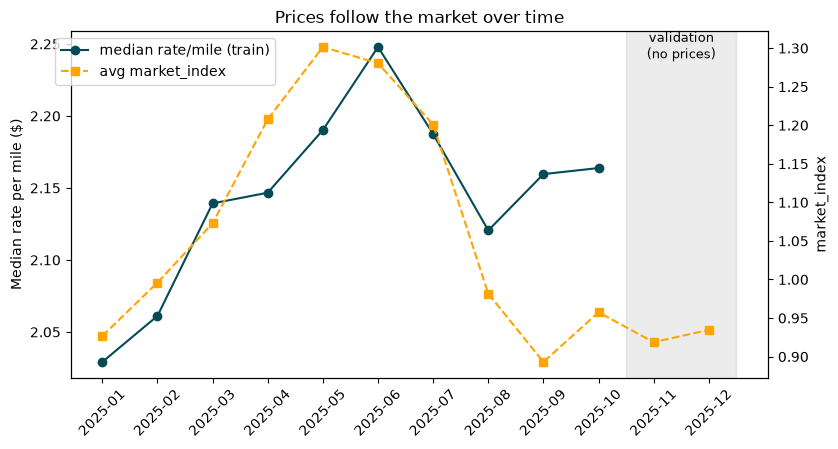

In [4]:
m_train = train.groupby(train.date.dt.to_period('M')).agg(rpm=('rpm', 'median'), mi=('market_index', 'mean'))
m_val = val.groupby(val.date.dt.to_period('M')).agg(mi=('market_index', 'mean'))

fig, ax1 = plt.subplots(figsize=(9, 4.5))
ax1.plot(m_train.index.astype(str), m_train.rpm, 'o-', color='#064A56', label='median rate/mile (train)')
ax1.set_ylabel('Median rate per mile ($)')
ax2 = ax1.twinx()                                            # second y-axis for market_index
mi = pd.concat([m_train.mi, m_val.mi])
ax2.plot(mi.index.astype(str), mi.values, 's--', color='orange', label='avg market_index')
ax2.set_ylabel('market_index')
ax1.axvspan(9.5, 11.5, color='grey', alpha=0.15)             # shade Nov-Dec (validation)
ax1.text(10.5, 2.24, 'validation\n(no prices)', fontsize=9, ha='center')
ax1.tick_params(axis='x', rotation=45)
ax1.set_title('Prices follow the market over time')
fig.legend(loc='upper left', bbox_to_anchor=(0.1, 0.88)); fig.savefig(FIG + '03_monthly_trend.png', dpi=130, bbox_inches='tight')

## Chart 4: data-quality problems to fix in step 2
Missing and negative values appear in **both** train and validation, so the cleaning must be applied to both. The negative weights look like flipped signs: their size (5k-47.5k lb) matches normal weights. Weights are also capped at 47,500 lb (the spike on the right).

                      train  validation
weight missing          300         165
weight negative         292         145
market_index missing    374         249


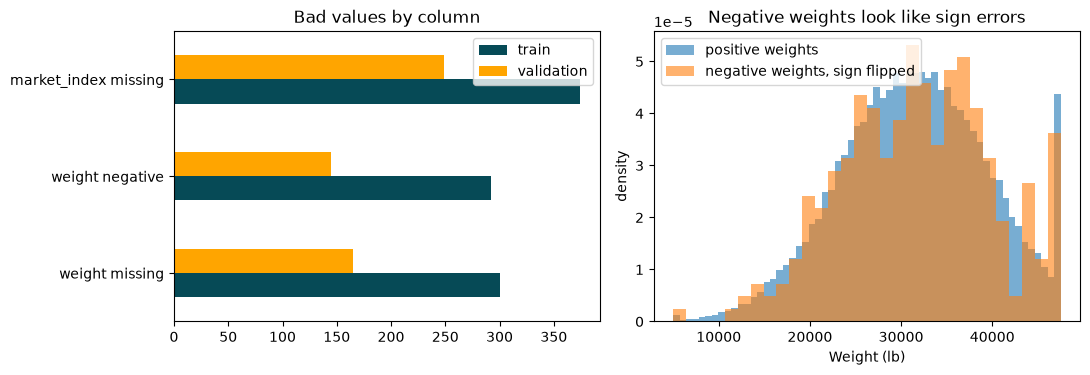

In [5]:
issues = pd.DataFrame({
    'train': [train.weight.isna().sum(), (train.weight < 0).sum(), train.market_index.isna().sum()],
    'validation': [val.weight.isna().sum(), (val.weight < 0).sum(), val.market_index.isna().sum()],
}, index=['weight missing', 'weight negative', 'market_index missing'])
print(issues)

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
issues.plot.barh(ax=axes[0], color=['#064A56', 'orange'])
axes[0].set_title('Bad values by column')
axes[1].hist(train.weight[train.weight > 0], bins=60, alpha=0.6, density=True, label='positive weights')
axes[1].hist(-train.weight[train.weight < 0], bins=30, alpha=0.6, density=True, label='negative weights, sign flipped')   # density=True so both shapes are comparable
axes[1].set(title='Negative weights look like sign errors', xlabel='Weight (lb)', ylabel='density'); axes[1].legend()
fig.tight_layout(); fig.savefig(FIG + '04_data_quality.png', dpi=130, bbox_inches='tight')

## Unseen cities
Some validation cities never appear in training, so a model keyed on city names would fail there. We'll use coordinates and distance instead.

In [6]:
seen = set(train.pickup) | set(train.delivery)
unseen = sorted((set(val.pickup) | set(val.delivery)) - seen)
share = (val.pickup.isin(unseen) | val.delivery.isin(unseen)).mean()
print(len(unseen), 'unseen cities:', unseen)
print(f'{share:.1%} of validation loads touch an unseen city')

8 unseen cities: ['Allentown', 'Charlotte', 'Chicago', 'Jackson', 'Knoxville', 'Laredo', 'Norfolk', 'San Diego']
12.1% of validation loads touch an unseen city
